# 01 · Exact search, and why it fails

**The question.** Given a query vector, which stored vectors are closest to it? Every semantic
search box, recommender, RAG pipeline and "find similar" button asks this thousands of times a
second.

**The claim.** The honest answer — compute the distance to *every* stored vector and keep the
smallest — is a few lines of code, always exactly right, and hopelessly slow at scale, because
its cost grows in lockstep with the database. No amount of tuning changes the fact that it has
to look at everything.

**By the end** you will have built brute-force k-nearest-neighbour search, used it to define the
*ground truth* every later notebook is scored against, and measured the wall it runs into.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import visualisation as vis
from src.artifacts import save_figure, save_json
from src.config import get_settings
from src.datasets.vectors import load_dataset
from src.evaluation.speed import machine_info, pinned_threads

S = get_settings()
K, SEED, THREADS = S.eval.k, S.seed, S.bench.threads
NB_START = time.perf_counter()
MACHINE = machine_info(THREADS)
pd.set_option("display.width", 140, "display.max_colwidth", 90)


def show(fig, slug: str) -> None:
    """Save the figure as outputs/figures/<slug>.png, then display it once."""
    save_figure(fig, slug)
    plt.close(fig)
    display(fig)


print(MACHINE)

{'cpu': 'Intel(R) Xeon(R) Platinum 8370C CPU @ 2.80GHz', 'logical_cpus': 2, 'threads': 1, 'python': '3.14.2', 'numpy': '2.5.4', 'faiss': '1.15.1', 'hnswlib': '0.8.0'}


## The baseline in a few lines

The vectors are 50,000 sentences from the 20 Newsgroups corpus, embedded with the small
sentence-transformer `all-MiniLM-L6-v2` into 384 dimensions and scaled to unit length (built and
cached by `make data`). A held-out set of 1,000 sentences serves as queries; none of them is in
the database, so a query can never trivially find itself.

Exact search is literally this: one distance per stored vector, then the k smallest.

In [2]:
news = load_dataset("news")
xb, xq = news.base, news.queries
print(f"database: {news.n:,} vectors x {news.d} dims | queries: {xq.shape[0]:,} (held out)")

qi = next(i for i, t in enumerate(news.query_texts) if len(t.split()) >= 12)  # a readable example
q = xq[qi]
dists = ((xb - q) ** 2).sum(axis=1)  # one squared distance per stored vector: N of them
top = np.argsort(dists)[:K]  # the K smallest

example = pd.DataFrame(
    {"rank": np.arange(1, K + 1), "distance": dists[top].round(3), "sentence": [news.texts[i] for i in top]}
)
print("query:", news.query_texts[qi])
display(example.head(5))
save_json("01_example_neighbours", {
    "query": news.query_texts[qi], "query_index": qi, "k": K,
    "neighbours": example.to_dict(orient="records"),
})

database: 50,000 vectors x 384 dims | queries: 1,000 (held out)
query: "The Divine Invasion" God invades Earth by making a young woman pregnant as she returns from another star system.


,rank,distance,sentence
0,1,0.772,So Mary comes up with this ridiculous story about God making her pregnant.
1,2,1.010,But it doesn't imply that God's sperm was involved.
2,3,1.033,At least it has a fairly popular orginating premise; everyone I'd mention the idea to ...
3,4,1.036,I could just see it now: Mary gets pregnant out of wedlock so to save face she and Jos...
4,5,1.048,The Bible in one place refers to God as being like a mother.


PosixPath('/workspaces/vector_search_101/outputs/results/01_example_neighbours.json')

The library version (`src/indexes/exact.py`) does the same thing faster: it uses the expansion
$\lVert q - x\rVert^2 = \lVert q\rVert^2 + \lVert x\rVert^2 - 2\,q\cdot x$ so the heavy lifting is
one matrix multiply, and `argpartition` finds the k smallest in O(N) instead of sorting all N.
Before trusting it as the definition of "correct", check it against the textbook version and
against faiss's `IndexFlatL2`.

In [3]:
from src.evaluation.recall import recall_at_k
from src.indexes.exact import ExactIndex
from src.reference.compare import FaissFlat

exact = ExactIndex()
exact.add(xb)
_, ids_lib = exact.search(xq[:200], K)

naive = np.stack([np.argsort(((xb - v) ** 2).sum(axis=1))[:K] for v in xq[:200]])
flat = FaissFlat()
flat.add(xb)
_, ids_faiss = flat.search(xq[:200], K)

check = {
    "queries_checked": 200,
    "k": K,
    "library_vs_naive_identical_rows": int((ids_lib == naive).all(axis=1).sum()),
    "library_vs_faiss_recall": recall_at_k(ids_lib, ids_faiss, K),
    "library_vs_cached_ground_truth_recall": recall_at_k(ids_lib, news.gt_ids[:200], K),
}
assert check["library_vs_naive_identical_rows"] == 200
assert check["library_vs_cached_ground_truth_recall"] == 1.0
save_json("01_ground_truth_check", check)
check

{'queries_checked': 200,
 'k': 10,
 'library_vs_naive_identical_rows': 200,
 'library_vs_faiss_recall': 1.0,
 'library_vs_cached_ground_truth_recall': 1.0}

Identical on every query. From here on, `news.gt_ids` — the exact top-100 neighbours of each
query, computed once by this brute force — is the truth. Every approximate index in the project
is scored by **recall@10**: the share of the 10 true neighbours it actually returns.

## Every query touches every vector

To return 10 sentences, exact search had to score all 50,000. The distances pile up in a broad
hump; the 10 we want sit at the far left edge — and there is no way to know which ones they are
without computing the rest.

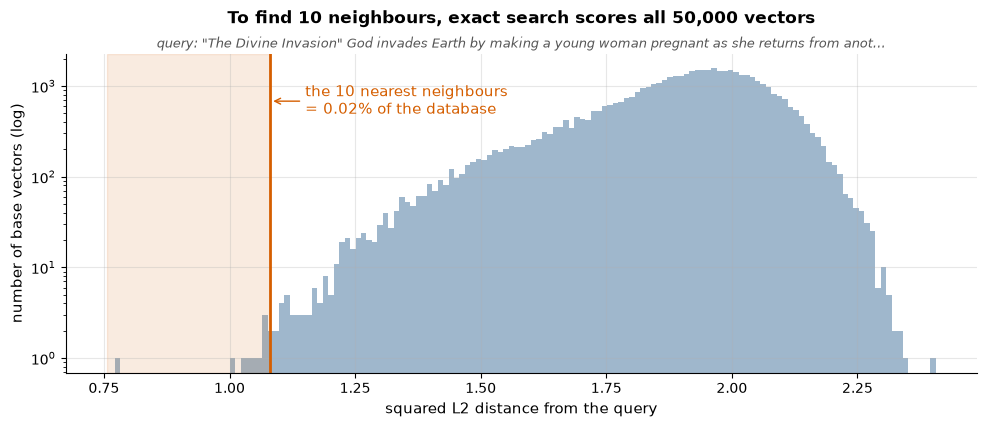

PosixPath('/workspaces/vector_search_101/outputs/results/01_needle_in_haystack.json')

In [4]:
kth = float(np.sort(dists)[K - 1])
fig = vis.plot_needle(dists, K, news.query_texts[qi])
show(fig, "01_needle_in_haystack")
save_json("01_needle_in_haystack", {
    "n": news.n, "k": K, "kth_distance": kth,
    "median_distance": float(np.median(dists)),
    "share_of_database_wanted": K / news.n,
    "distances_computed": news.n,
})

## The wall: query time as the database grows

Exact search does `N × d` multiply-adds per query, so its time should grow linearly with N. The
content of the vectors does not matter for that, so the measurement uses random unit vectors at
the same 384 dimensions, from 10,000 up to 500,000 (768 MB of floats — about as far as an
8 GB Codespace comfortably goes). Each point is the median of single-query searches on one
thread, for both our numpy implementation and faiss's BLAS-backed `IndexFlatL2`.

In [5]:
from src.evaluation.speed import median_latency_ms

sc = S.scaling
rng = np.random.default_rng(SEED)
n_max = max(sc.sizes)
pool = rng.standard_normal((n_max, sc.d), dtype=np.float32)
pool /= np.linalg.norm(pool, axis=1, keepdims=True)
probe = rng.standard_normal((sc.n_queries, sc.d), dtype=np.float32)
probe /= np.linalg.norm(probe, axis=1, keepdims=True)

rows = []
with pinned_threads(THREADS):
    for n in sc.sizes:
        idx = ExactIndex()
        idx.add(pool[:n])
        ms_numpy = median_latency_ms(idx, probe, K, warmup=S.bench.warmup)
        del idx
        ref = FaissFlat()
        ref.add(pool[:n])
        ms_faiss = median_latency_ms(ref, probe, K, warmup=S.bench.warmup)
        del ref
        rows.append({"n": n, "numpy_ms": ms_numpy, "faiss_ms": ms_faiss, "memory_mb": n * sc.d * 4 / 1e6})
del pool
scaling = pd.DataFrame(rows)

slope, intercept = np.polyfit(scaling["n"], scaling["numpy_ms"], 1)
pred = intercept + slope * scaling["n"]
r2 = 1 - ((scaling["numpy_ms"] - pred) ** 2).sum() / ((scaling["numpy_ms"] - scaling["numpy_ms"].mean()) ** 2).sum()
extrapolated = {int(n): intercept + slope * n for n in sc.extrapolate_to}
display(scaling.round(2))
print(f"linear fit: {slope * 1e6:.2f} ms per million vectors (+{intercept:.2f} ms), R² = {r2:.4f}")

,n,numpy_ms,faiss_ms,memory_mb
0,10000,0.59,0.56,15.36
1,30000,3.46,3.22,46.08
2,100000,12.02,12.94,153.60
3,200000,25.73,27.51,307.20
4,500000,61.14,62.98,768.00


linear fit: 123.43 ms per million vectors (+-0.15 ms), R² = 0.9992


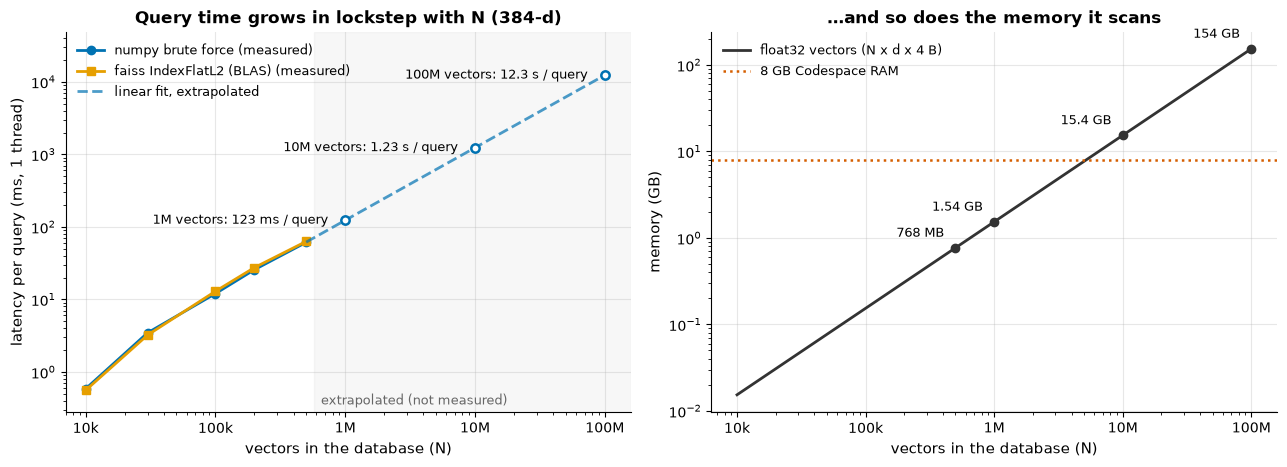

PosixPath('/workspaces/vector_search_101/outputs/results/01_scaling_wall.json')

In [6]:
fig = vis.plot_scaling_wall(
    scaling["n"], {"numpy": scaling["numpy_ms"], "faiss": scaling["faiss_ms"]},
    slope, intercept, sc.extrapolate_to, sc.d,
)
show(fig, "01_scaling_wall")
save_json("01_scaling_wall", {
    "d": sc.d, "threads": THREADS, "queries_timed": sc.n_queries, "machine": MACHINE,
    "measured": scaling, "fit": {"ms_per_vector": slope, "intercept_ms": intercept, "r2": r2},
    "extrapolated_ms": extrapolated,
    "extrapolated_memory_gb": {int(n): n * sc.d * 4 / 1e9 for n in sc.extrapolate_to},
})

The line is straight: double the database, double the wait. The extrapolated points are not
measured (the memory alone would not fit), but nothing about brute force changes past the last
measured point — it is the same loop, just longer.

`retrieval_arena` measured the same thing on real embeddings (100K ≈ 13 ms, 500K ≈ 60 ms per
query) and concluded that **below a few hundred thousand vectors numpy brute force is genuinely
fine**. That remains true. This project starts where that one stops: what to do when the line
above leaves your latency budget.

## The thesis

Exact search cannot get faster without looking at fewer vectors. Any method that looks at fewer
vectors can miss a true neighbour that sat among the ones it skipped. So **every fast search is
approximate**: it trades a measurable miss rate (1 − recall) for speed, memory, or both. The
next three notebooks build the three families that make that trade — inverted files, product
quantization and HNSW — and notebook 05 puts them on one chart.

In [7]:
one_m, hundred_m = extrapolated[1_000_000], extrapolated[100_000_000]
at_500k = scaling.loc[scaling["n"] == max(sc.sizes)]
summary = {
    "exact_matches_naive_and_faiss": True,
    "latency_ms_at_500k_numpy": float(at_500k["numpy_ms"].iloc[0]),
    "latency_ms_at_500k_faiss": float(at_500k["faiss_ms"].iloc[0]),
    "extrapolated_ms_1m": one_m, "extrapolated_ms_100m": hundred_m, "fit_r2": r2,
    "runtime_s": time.perf_counter() - NB_START,
}
save_json("01_summary", summary)
display(Markdown(f'''
### What this bought you, and what it cost

- **Bought:** a search that is exactly right — it matches the textbook version and faiss on every
  query checked — and the ground truth every later notebook is scored against.
- **Cost:** {summary["latency_ms_at_500k_numpy"]:.0f} ms per query at 500,000 vectors on one thread
  (faiss: {summary["latency_ms_at_500k_faiss"]:.0f} ms), growing linearly (R² = {r2:.3f}).
  Extrapolated: {vis.human_ms(one_m)} at a million vectors, {vis.human_ms(hundred_m)} at a hundred
  million — plus {100_000_000 * sc.d * 4 / 1e9:.0f} GB of RAM just to hold the floats.
'''))
print(f"notebook runtime: {summary['runtime_s']:.0f} s")


### What this bought you, and what it cost

- **Bought:** a search that is exactly right — it matches the textbook version and faiss on every
  query checked — and the ground truth every later notebook is scored against.
- **Cost:** 61 ms per query at 500,000 vectors on one thread
  (faiss: 63 ms), growing linearly (R² = 0.999).
  Extrapolated: 123 ms at a million vectors, 12.3 s at a hundred
  million — plus 154 GB of RAM just to hold the floats.


notebook runtime: 30 s
